# P1.03 — Thirty years of house prices, rents and affordability (national)

**Questions:** RQ1.1 (how prices evolved over 30 years), RQ1.3 (in real terms), RQ1.4 (relative to income).
The municipal evidence starts in 2016 (prices) and 2015 (income) and INE's own price index in 2009, so the long view
is national. Two sources extend it (`docs/data_catalog.md`):

* **BIS residential property prices** (`bis_spp`): quarterly index, 1988-Q1 onwards. From 2009 it **is** INE's index
  (ratio constant to four decimals over 69 quarters); before 2009 it is the BIS compilation of national sources, and
  there is no overlap with another index to test how the two join. Its "real" series uses the INE CPI exactly.
* **OECD analytical house price indicators** (`oecd_house_prices`): annual nominal price index (same growth as the BIS
  to within 0.3 points, except 2009, the join year: -0.9% in the BIS, +0.2% in the OECD), rents from 1959, the
  price-to-rent ratio from 1988 and the **price-to-income ratio from 1995** (nominal price over nominal disposable
  income per head).

Real values use the project's CPI deflator, not the OECD's own real series (it deflates differently, up to 4% apart).
`build_panel.national_annual_long` holds the table; `validate.py` checks it.

In [1]:
import numpy as np
import pandas as pd

from pthousing.data import build_panel
from pthousing.viz import charts, dashboard, style

style.apply_style()
long = build_panel.read("national_annual_long")
panel = dashboard.load_panel()
d = long.set_index("year")
print(
    f"{d.index.min()} to {d.index.max()}; price-to-income from {d['price_to_income_b2015'].first_valid_index()}"
)
long.round(1).tail(8)

1988 to 2025; price-to-income from 1995


,year,hpi_nominal_b2015,hpi_real_b2015,cpi_index_b2015,rent_index_b2015,price_to_rent_b2015,price_to_income_b2015,price_to_rent_std,price_to_income_std,rent_real_b2015
30,2018,129.0,125.3,103.0,104.7,123.3,116.7,90.4,92.8,101.6
31,2019,141.9,137.3,103.3,108.0,131.4,123.2,96.3,98.0,104.5
32,2020,154.3,149.3,103.3,110.8,139.3,136.6,102.1,108.6,107.2
33,2021,168.8,161.3,104.6,112.8,149.7,142.0,109.8,112.9,107.8
34,2022,190.2,168.5,112.8,115.8,164.2,148.2,120.4,117.8,102.6
35,2023,205.8,174.8,117.7,121.1,170.0,147.4,124.6,117.2,102.8
36,2024,224.4,186.2,120.5,129.5,173.2,147.3,127.0,117.1,107.4
37,2025,263.8,213.9,123.4,136.4,193.4,166.7,141.8,132.6,110.5


## Step 1 — The long picture
The dotted line marks 2009, where the price series changes source; read changes across it with caution.

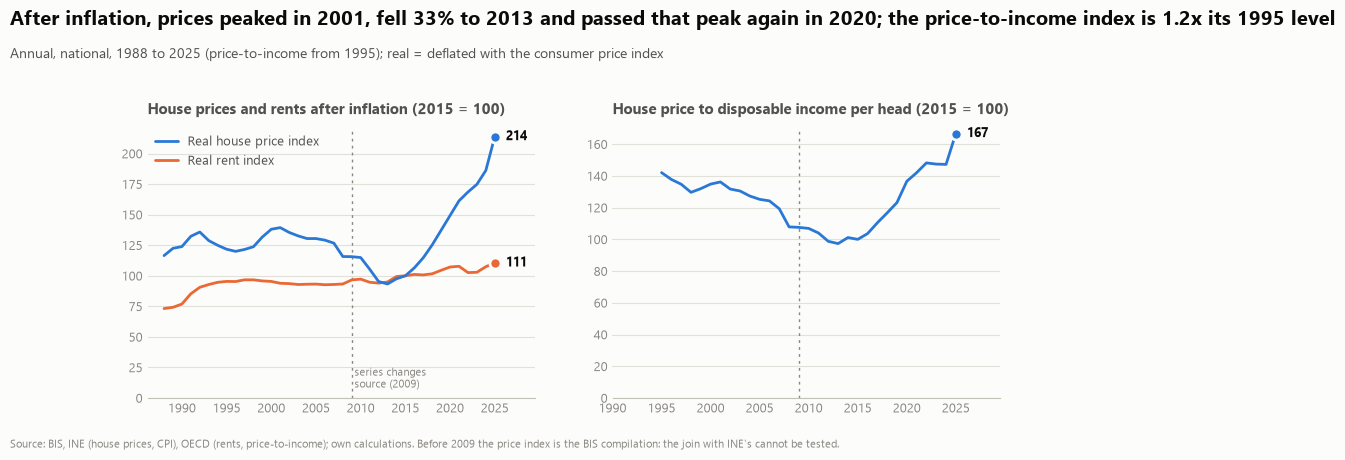

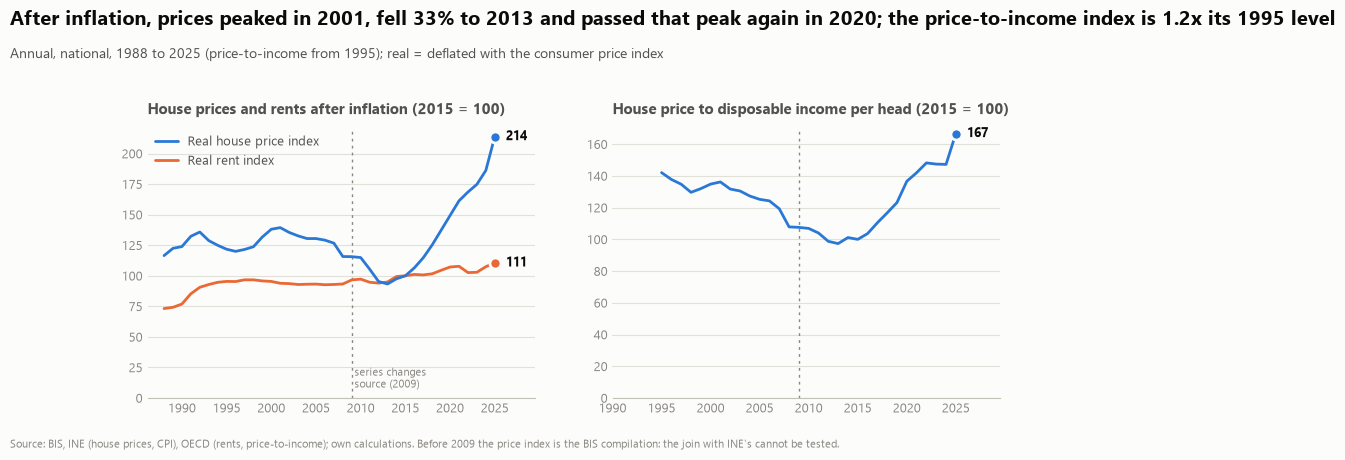

In [2]:
fig = charts.long_run_prices(long)
style.save_fig(fig, "p1", "long_run_prices")
fig

## Step 2 — Cycles in numbers

In [3]:
real, rent, pti, std = (
    d["hpi_real_b2015"],
    d["rent_real_b2015"],
    d["price_to_income_b2015"],
    d["price_to_income_std"],
)
peak = int(real.loc[:2012].idxmax())
low = int(real.loc[peak:].idxmin())
back = int(real[(real.index > low) & (real > real.loc[peak])].index.min())
pti_low = int(pti.loc[:2016].idxmin())
summary = pd.DataFrame(
    [
        ("Real house prices: first peak", peak, real.loc[peak]),
        ("Real house prices: low", low, real.loc[low]),
        (
            "Real house prices: fall, peak to low (%)",
            f"{peak}-{low}",
            100 * (real.loc[low] / real.loc[peak] - 1),
        ),
        ("Real house prices: passed the first peak again", back, real.loc[back]),
        ("Real house prices: last year", int(d.index.max()), real.iloc[-1]),
        (
            "Real house prices: last year over low (x)",
            int(d.index.max()),
            real.iloc[-1] / real.loc[low],
        ),
        ("Real rents: 1988", 1988, rent.loc[1988]),
        ("Real rents: last year", int(d.index.max()), rent.iloc[-1]),
        ("Price-to-income: 1995", 1995, pti.loc[1995]),
        ("Price-to-income: low", pti_low, pti.loc[pti_low]),
        ("Price-to-income: last year", int(pti.index.max()), pti.iloc[-1]),
        (
            "Price-to-income vs long-term average, last year (100 = average)",
            int(std.dropna().index.max()),
            std.dropna().iloc[-1],
        ),
    ],
    columns=["indicator", "year", "value"],
)
style.save_table(
    summary.assign(value=summary["value"].astype(float).round(2)), "p1", "long_run_summary"
)
summary.assign(value=summary["value"].astype(float).round(1))

,indicator,year,value
0,Real house prices: first peak,2001,139.4
1,Real house prices: low,2013,93.3
2,"Real house prices: fall, peak to low (%)",2001-2013,-33.1
3,Real house prices: passed the first peak again,2020,149.3
4,Real house prices: last year,2025,213.9
5,Real house prices: last year over low (x),2025,2.3
6,Real rents: 1988,1988,73.2
7,Real rents: last year,2025,110.5
8,Price-to-income: 1995,1995,142.1
9,Price-to-income: low,2013,97.3


## Step 3 — Does the national ratio agree with the municipal one?
The OECD ratio (price over income **per head**, national) and the project's (price of an average-size home over income
**per tax household**, by municipality) are different concepts, so levels cannot be compared; changes can, between 2016
(the first year of the municipal ratio) and 2024 (the last: 2025 income is not published yet). The national index is
weighted by transactions, so the fair municipal comparison weights municipalities by their sales (2024 sales: no counts are
published for 2016). The median municipality, unweighted, is a typical inland one.

In [4]:
pt = panel[panel["territory"] == "continente"]
both = pt.pivot(index="muni_code", columns="year", values="pti_years")[[2016, 2024]].dropna()
sales = pt[pt["year"] == 2024].set_index("muni_code")["sales_12m_n"].reindex(both.index).fillna(0)
change = np.log(both[2024] / both[2016])
order = change.sort_values().index
weighted_median = change.loc[order][(sales.loc[order].cumsum() / sales.sum()) >= 0.5].iloc[0]
density = (
    pt.drop_duplicates("muni_code").set_index("muni_code")["density_class"].reindex(both.index)
)
urban_sales = float(sales[density == "urban"].sum() / sales.sum())
agree = pd.DataFrame(
    {
        "measure": [
            "OECD price-to-income (national, per head)",
            "Median municipality (unweighted)",
            "Municipalities weighted by 2024 sales: mean",
            "Municipalities weighted by 2024 sales: median",
            "Real price index (national)",
        ],
        "change_2016_2024_pct": [
            100 * (pti.loc[2024] / pti.loc[2016] - 1),
            100 * np.expm1(change.median()),
            100 * np.expm1(np.average(change, weights=sales)),
            100 * np.expm1(weighted_median),
            100 * (real.loc[2024] / real.loc[2016] - 1),
        ],
    }
)
style.save_table(agree.round(2), "p1", "national_vs_municipal_pti")
print(
    f"{len(both)} municipalities with both years; urban municipalities: {(density == 'urban').sum()}, {100 * urban_sales:.0f}% of sales"
)
agree.round(1)

271 municipalities with both years; urban municipalities: 32, 46% of sales


,measure,change_2016_2024_pct
0,"OECD price-to-income (national, per head)",42.1
1,Median municipality (unweighted),18.8
2,Municipalities weighted by 2024 sales: mean,48.7
3,Municipalities weighted by 2024 sales: median,52.8
4,Real price index (national),74.9


## What this says
See `reports/p1_evidence.md` (thirty years) for the reading and the limits. Tables: `reports/tables/p1/long_run_*.csv`,
`national_vs_municipal_pti.csv`.